# DeepLabV3+ Semantic Segmentation — Dataset 2 (2.coco)

This notebook trains a **DeepLabV3+** model on the `2.coco` split of your SEM/wafer dataset (COCO polygon format, Roboflow export) and produces:

- ✅ Training / validation **loss curve**
- ✅ Pixel-wise **confusion matrix** on the test set
- ✅ A **comparison table** with Accuracy, Precision, Recall, F1-score

**Dataset size:** 46 train / 13 valid / 6 test images.

**Before running:**
1. Add your dataset via *Add Data* (top right) so it appears under `/kaggle/input/...`. You can upload all three `1.coco` / `2.coco` / `3.coco` folders together in one dataset, or separately — this notebook auto-detects `2.coco` specifically either way.
2. Go to **Settings → Accelerator → GPU T4 x2** (or P100)
3. Go to **Settings → Internet → On** (required to `pip install segmentation-models-pytorch`)
4. Run cells top to bottom.


## Step 1 — Install & import libraries

We use [`segmentation-models-pytorch`](https://github.com/qubvel/segmentation_models.pytorch) for a battle-tested DeepLabV3+ implementation with pretrained encoders, `pycocotools` to decode the COCO polygon annotations into masks, and `albumentations` for augmentation.

In [1]:
!pip install -q segmentation-models-pytorch pycocotools albumentations

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 9.7 MB/s eta 0:00:00


In [2]:
import os
import re
import json
import time
import random

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import albumentations as A
from albumentations.pytorch import ToTensorV2

from pycocotools.coco import COCO
import segmentation_models_pytorch as smp

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    accuracy_score,
)
from tqdm import tqdm

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)
print("Torch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())

Torch: 2.10.0+cu128 | CUDA available: True


## Step 2 — Locate the `2.coco` dataset

Kaggle mounts uploaded datasets under `/kaggle/input/<dataset-name>/...`. Run the cell below to see what's actually there.

In [3]:
!ls /kaggle/input/
print()
for root, dirs, files in os.walk("/kaggle/input"):
    depth = root.replace("/kaggle/input", "").count(os.sep)
    if depth <= 3:
        print(root)

datasets

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/sarthakjadhav07
/kaggle/input/datasets/sarthakjadhav07/sem-dataset-2


### Auto-detect the `2.coco` train / valid / test folders

This cell searches the entire `/kaggle/input` tree for folders containing `_annotations.coco.json`, then matches each one to `train` / `valid` / `test` **specifically for `2.coco`** — important since you may have `1.coco`, `2.coco`, and `3.coco` all uploaded together, each with their own `train/valid/test` subfolders. Matching is done on a normalized (punctuation-stripped) path, so it's resilient to however Kaggle slugifies the folder name.

If it can't confidently match a `2.coco`-tagged folder, it falls back to the only folder of that split type found anywhere (safe only if just one dataset is present), and otherwise prints every candidate so you can set the path manually.

In [4]:
DATASET_TAG = "2.coco"  # this notebook trains on this dataset specifically


def _normalize(s):
    return re.sub(r"[^a-z0-9]", "", s.lower())


tag_norm = _normalize(DATASET_TAG)

ann_dirs = []
for root, dirs, files in os.walk("/kaggle/input"):
    if "_annotations.coco.json" in files:
        ann_dirs.append(root)

print(f"Found {len(ann_dirs)} folder(s) containing _annotations.coco.json:")
for d in ann_dirs:
    print(" ", d)

if len(ann_dirs) == 0:
    raise FileNotFoundError(
        "No _annotations.coco.json found anywhere under /kaggle/input. "
        "Make sure the dataset was attached via 'Add Data' and finished uploading."
    )


def match_split(split_name):
    tagged = [d for d in ann_dirs
              if split_name in os.path.basename(d).lower() and tag_norm in _normalize(d)]
    if tagged:
        if len(tagged) > 1:
            print(f"Warning: multiple '{split_name}' matches for tag '{DATASET_TAG}': {tagged}. Using first.")
        return tagged[0]

    fallback = [d for d in ann_dirs if split_name in os.path.basename(d).lower()]
    if len(fallback) == 1:
        print(f"Note: no folder matched tag '{DATASET_TAG}' for split '{split_name}'; "
              f"falling back to the only '{split_name}' folder found: {fallback[0]}")
        return fallback[0]
    elif len(fallback) > 1:
        print(f"Could not disambiguate '{split_name}' for tag '{DATASET_TAG}'. "
              f"Candidates: {fallback} -- set train_dir/valid_dir/test_dir manually below.")
        return None
    return None


train_dir = match_split("train")
valid_dir = match_split("valid") or match_split("val")
test_dir  = match_split("test")

print("\nAuto-detected paths for", DATASET_TAG)
print("  TRAIN:", train_dir)
print("  VALID:", valid_dir)
print("  TEST :", test_dir)

if not (train_dir and valid_dir and test_dir):
    print("\n*** Auto-detection could not confidently match all 3 splits for this tag. ***")
    print("*** Set train_dir / valid_dir / test_dir manually above using the printed candidate list, then re-run. ***")

Found 3 folder(s) containing _annotations.coco.json:
  /kaggle/input/datasets/sarthakjadhav07/sem-dataset-2/SEM wafer dataset-Folder- 2.coco/valid
  /kaggle/input/datasets/sarthakjadhav07/sem-dataset-2/SEM wafer dataset-Folder- 2.coco/test
  /kaggle/input/datasets/sarthakjadhav07/sem-dataset-2/SEM wafer dataset-Folder- 2.coco/train

Auto-detected paths for 2.coco
  TRAIN: /kaggle/input/datasets/sarthakjadhav07/sem-dataset-2/SEM wafer dataset-Folder- 2.coco/train
  VALID: /kaggle/input/datasets/sarthakjadhav07/sem-dataset-2/SEM wafer dataset-Folder- 2.coco/valid
  TEST : /kaggle/input/datasets/sarthakjadhav07/sem-dataset-2/SEM wafer dataset-Folder- 2.coco/test


In [5]:
class CFG:
    TRAIN_DIR = train_dir
    VALID_DIR = valid_dir
    TEST_DIR  = test_dir

    TRAIN_ANN = os.path.join(TRAIN_DIR, "_annotations.coco.json")
    VALID_ANN = os.path.join(VALID_DIR, "_annotations.coco.json")
    TEST_ANN  = os.path.join(TEST_DIR, "_annotations.coco.json")

    IMG_SIZE   = 512
    BATCH_SIZE = 4
    EPOCHS     = 40
    LR         = 1e-4
    WEIGHT_DECAY = 1e-3  # increased from 1e-4 - stronger L2 regularization, since train/test gap indicates overfitting

    ENCODER         = "resnet18"     # lighter than resnet34 - fewer parameters overfit less on very small datasets
    ENCODER_WEIGHTS = "imagenet"

    NUM_WORKERS = 2
    SEED = 42
    PATIENCE = 12  # early stopping patience (epochs with no val-loss improvement)
    MIN_BLOB_AREA = 15  # predicted foreground blobs smaller than this (pixels) are treated as noise
    TRAIN_MULTIPLIER = 2  # each training image is sampled this many times per epoch, each with independent random augmentation

    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", CFG.DEVICE)
assert os.path.exists(CFG.TRAIN_ANN), f"Could not find {CFG.TRAIN_ANN} - check train_dir above"
assert os.path.exists(CFG.VALID_ANN), f"Could not find {CFG.VALID_ANN} - check valid_dir above"
assert os.path.exists(CFG.TEST_ANN),  f"Could not find {CFG.TEST_ANN} - check test_dir above"
print("All annotation files located successfully.")

Device: cuda
All annotation files located successfully.


## Step 3 — Inspect COCO annotations & build the class map

We read the categories directly from `_annotations.coco.json` so the notebook adapts automatically to however many defect classes your dataset has (background is always class `0`).

**Important Roboflow quirk:** COCO exports from Roboflow always include an auto-generated placeholder category (typically `id=0`, named after the project itself) that has zero real annotations — it exists for schema/hierarchy reasons, not because it's a usable class. If we don't filter it out, it shows up in the metrics table later as a class with 0 precision/recall/F1 (because it's never actually present in any image), which is misleading. The cell below keeps only categories that have at least one real annotation somewhere in the dataset.

In [6]:
coco_train = COCO(CFG.TRAIN_ANN)
coco_valid = COCO(CFG.VALID_ANN)
coco_test  = COCO(CFG.TEST_ANN)

raw_cat_ids = sorted(coco_train.getCatIds())
raw_cats = coco_train.loadCats(raw_cat_ids)
print("Raw categories declared in the COCO json:")
for c in raw_cats:
    print(f"  id={c['id']:>3}  name={c['name']!r}  supercategory={c.get('supercategory')}")


def categories_with_annotations(*coco_objs):
    used = set()
    for coco in coco_objs:
        for ann in coco.anns.values():
            used.add(ann["category_id"])
    return used


used_cat_ids = categories_with_annotations(coco_train, coco_valid, coco_test)
cat_ids = sorted(cid for cid in raw_cat_ids if cid in used_cat_ids)
dropped = [c for c in raw_cats if c["id"] not in used_cat_ids]

if dropped:
    print("\nDropping placeholder/empty categories with 0 annotations anywhere in the dataset:")
    for c in dropped:
        print(f"  id={c['id']} name={c['name']!r}")
else:
    print("\nNo empty placeholder categories found.")

cats = coco_train.loadCats(cat_ids)

# map raw category_id -> contiguous class index (0 = background)
cat_id_to_class = {cid: i + 1 for i, cid in enumerate(cat_ids)}
CLASS_NAMES = ["background"] + [c["name"] for c in cats]
CFG.NUM_CLASSES = len(CLASS_NAMES)

print("\nFinal class map (category_id -> model class index):", cat_id_to_class)
print("CLASS_NAMES:", CLASS_NAMES)
print("NUM_CLASSES:", CFG.NUM_CLASSES)

n_train_imgs = len(coco_train.imgs)
n_train_anns = len(coco_train.anns)
print(f"\nTrain images: {n_train_imgs} | Train annotations: {n_train_anns}")

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Raw categories declared in the COCO json:
  id=  0  name='SEM-wafer-dataset'  supercategory=none
  id=  1  name='SEM-wafer-dataset'  supercategory=SEM-wafer-dataset

Dropping placeholder/empty categories with 0 annotations anywhere in the dataset:
  id=0 name='SEM-wafer-dataset'

Final class map (category_id -> model class index): {1: 1}
CLASS_NAMES: ['background', 'SEM-wafer-dataset']
NUM_CLASSES: 2

Train images: 46 | Train annotations: 95


### Data-quality check: scan for malformed annotations

Roboflow COCO exports sometimes include annotations with an empty `segmentation` field (e.g. an object that was only bbox-labeled, never polygon-labeled) or a polygon with fewer than 3 points. `pycocotools` crashes on these. The dataset class below is written to skip them safely, but it's worth knowing up front how many (if any) exist in your data.

In [7]:
def scan_annotation_quality(ann_path, split_name):
    coco = COCO(ann_path)
    total = 0
    empty_seg = 0
    malformed_poly = 0
    for ann in coco.anns.values():
        total += 1
        seg = ann.get("segmentation", None)
        if not seg:
            empty_seg += 1
            continue
        if isinstance(seg, list):
            if not any(isinstance(p, list) and len(p) >= 6 for p in seg):
                malformed_poly += 1
    ok = total - empty_seg - malformed_poly
    print(f"{split_name:6s} | total: {total:4d} | usable: {ok:4d} | "
          f"empty segmentation: {empty_seg:3d} | malformed polygon: {malformed_poly:3d}")

scan_annotation_quality(CFG.TRAIN_ANN, "train")
scan_annotation_quality(CFG.VALID_ANN, "valid")
scan_annotation_quality(CFG.TEST_ANN, "test")

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
train  | total:   95 | usable:   90 | empty segmentation:   5 | malformed polygon:   0
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
valid  | total:   20 | usable:   20 | empty segmentation:   0 | malformed polygon:   0
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
test   | total:    8 | usable:    8 | empty segmentation:   0 | malformed polygon:   0


## Step 4 — Dataset class: COCO polygons → segmentation masks

For each image we build an `(H, W)` mask where every pixel holds the class index of the defect it belongs to (`0` = background). Annotations are painted largest-area-first so small defects aren't hidden underneath big overlapping polygons.

In [8]:
class COCOSegmentationDataset(Dataset):
    def __init__(self, images_dir, ann_path, cat_id_to_class, transform=None, multiplier=1):
        self.images_dir = images_dir
        self.coco = COCO(ann_path)
        self.image_ids = list(sorted(self.coco.imgs.keys()))
        self.cat_id_to_class = cat_id_to_class
        self.transform = transform
        self.multiplier = max(1, multiplier)

    def __len__(self):
        # multiplier > 1 makes each real image get sampled multiple times per
        # epoch; since self.transform re-rolls random augmentation on every
        # call, each pass produces a genuinely different augmented view.
        return len(self.image_ids) * self.multiplier

    def __getitem__(self, idx):
        img_id = self.image_ids[idx % len(self.image_ids)]
        img_info = self.coco.loadImgs(img_id)[0]
        img_path = os.path.join(self.images_dir, img_info["file_name"])

        image = cv2.imread(img_path)
        if image is None:
            raise FileNotFoundError(f"Could not read image: {img_path}")
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        h, w = img_info["height"], img_info["width"]
        mask = np.zeros((h, w), dtype=np.uint8)

        ann_ids = self.coco.getAnnIds(imgIds=img_id)
        anns = self.coco.loadAnns(ann_ids)
        # paint larger regions first so smaller defects remain visible on top
        anns = sorted(anns, key=lambda a: a.get("area", 0), reverse=True)

        for ann in anns:
            cls_idx = self.cat_id_to_class.get(ann["category_id"])
            if cls_idx is None:
                continue

            # Roboflow COCO exports occasionally contain empty or malformed
            # polygons (e.g. bbox-only annotations with segmentation=[], or a
            # polygon with fewer than 3 points). pycocotools crashes on these,
            # which kills the whole DataLoader worker. Validate and skip instead.
            seg = ann.get("segmentation", None)
            if not seg:
                continue
            if isinstance(seg, list):
                valid_polys = [p for p in seg if isinstance(p, list) and len(p) >= 6]
                if not valid_polys:
                    continue
                ann = {**ann, "segmentation": valid_polys}

            try:
                ann_mask = self.coco.annToMask(ann)
            except Exception:
                # skip any annotation pycocotools still can't decode
                continue

            mask[ann_mask == 1] = cls_idx

        if self.transform is not None:
            augmented = self.transform(image=image, mask=mask)
            image, mask = augmented["image"], augmented["mask"]

        return image, mask.long()

## Step 5 — Augmentations

With very few training images, augmentation matters a lot — both for variety and for regularization. We use flips/rotation (SEM defect orientation is arbitrary), mild affine jitter, brightness/noise variation, and `CoarseDropout` (randomly blacks out small patches, forcing the model to not over-rely on any single region — a standard regularizer against overfitting on tiny datasets). `A.Affine` and `A.GaussNoise` are called with only the parameter names that are stable across recent albumentations releases — Kaggle's preinstalled version has been renaming/removing a few keyword arguments (`var_limit`, `mode`) release to release, so we avoid passing them and rely on sensible library defaults instead.

In [9]:
train_transform = A.Compose([
    A.Resize(CFG.IMG_SIZE, CFG.IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.Affine(translate_percent=(-0.05, 0.05), scale=(0.9, 1.1), rotate=(-15, 15), p=0.4),
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.4),
    A.GaussNoise(p=0.2),
    A.CoarseDropout(p=0.3),  # library defaults - avoids the kwarg-naming drift we hit with GaussNoise/Affine
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

val_transform = A.Compose([
    A.Resize(CFG.IMG_SIZE, CFG.IMG_SIZE),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

## Step 6 — Build DataLoaders

`persistent_workers=True` keeps the background worker processes alive between epochs instead of tearing them down and respawning them every time — with `num_workers>0` this avoids periodic slow epochs and noisy DataLoader-cleanup warnings.

`CFG.TRAIN_MULTIPLIER = 2` makes the training set behave as 2× its real size for the purposes of one epoch — each real image gets visited that many times, each with an independently-random augmentation, since `train_transform` re-rolls its random choices every call. This does **not** add new information, but with only 46 real training images it means meaningfully more (and more varied) gradient updates per epoch. Validation and test sets are left at their real size.

In [10]:
train_ds = COCOSegmentationDataset(CFG.TRAIN_DIR, CFG.TRAIN_ANN, cat_id_to_class, train_transform,
                                    multiplier=CFG.TRAIN_MULTIPLIER)
valid_ds = COCOSegmentationDataset(CFG.VALID_DIR, CFG.VALID_ANN, cat_id_to_class, val_transform)
test_ds  = COCOSegmentationDataset(CFG.TEST_DIR,  CFG.TEST_ANN,  cat_id_to_class, val_transform)

train_loader = DataLoader(train_ds, batch_size=CFG.BATCH_SIZE, shuffle=True,
                           num_workers=CFG.NUM_WORKERS, pin_memory=True, drop_last=True,
                           persistent_workers=(CFG.NUM_WORKERS > 0), prefetch_factor=2 if CFG.NUM_WORKERS > 0 else None)
valid_loader = DataLoader(valid_ds, batch_size=CFG.BATCH_SIZE, shuffle=False,
                           num_workers=CFG.NUM_WORKERS, pin_memory=True,
                           persistent_workers=(CFG.NUM_WORKERS > 0), prefetch_factor=2 if CFG.NUM_WORKERS > 0 else None)
test_loader  = DataLoader(test_ds, batch_size=1, shuffle=False,
                           num_workers=CFG.NUM_WORKERS, pin_memory=True,
                           persistent_workers=(CFG.NUM_WORKERS > 0), prefetch_factor=2 if CFG.NUM_WORKERS > 0 else None)

n_real_train = len(coco_train.imgs)
print(f"Train: {n_real_train} real images x{CFG.TRAIN_MULTIPLIER} multiplier = {len(train_ds)} per epoch | "
      f"Valid: {len(valid_ds)} images | Test: {len(test_ds)} images")

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Train: 46 real images x2 multiplier = 92 per epoch | Valid: 13 images | Test: 6 images


## Step 7 — Sanity check: visualize a few training samples

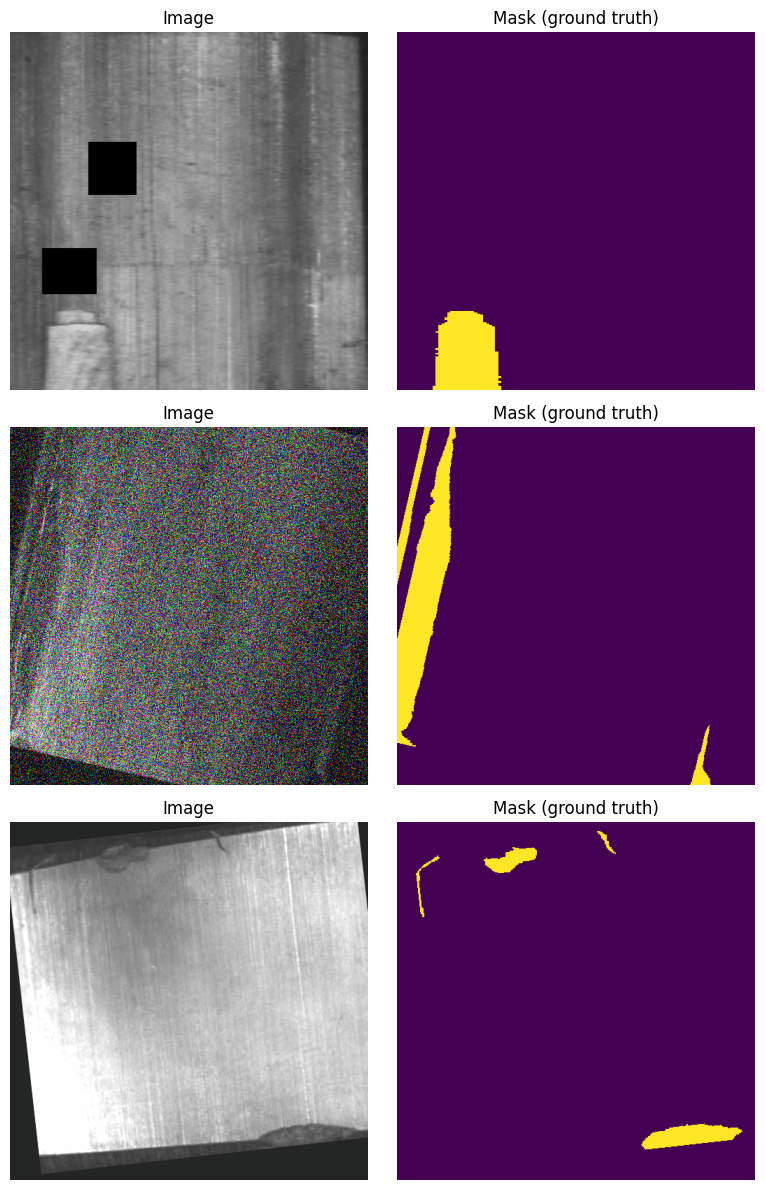

In [11]:
def denormalize(img_tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = img_tensor.permute(1, 2, 0).cpu().numpy()
    img = std * img + mean
    return np.clip(img, 0, 1)

fig, axes = plt.subplots(3, 2, figsize=(8, 12))
for i in range(3):
    img, mask = train_ds[i]
    axes[i, 0].imshow(denormalize(img))
    axes[i, 0].set_title("Image")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(mask.numpy(), cmap="viridis", vmin=0, vmax=CFG.NUM_CLASSES - 1)
    axes[i, 1].set_title("Mask (ground truth)")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

## Step 8 — Build the DeepLabV3+ model

We use a ResNet-18 encoder pretrained on ImageNet. This is a deliberate choice, not just for speed: a bigger encoder (ResNet-34/50) has more capacity to *memorize* a tiny training set rather than *generalize*, which is exactly the failure mode of a large train/test performance gap. ResNet-18 gives up some raw capacity in exchange for overfitting less on very few images. Swap `CFG.ENCODER` to try others once you have more data.

In [12]:
model = smp.DeepLabV3Plus(
    encoder_name=CFG.ENCODER,
    encoder_weights=CFG.ENCODER_WEIGHTS,
    in_channels=3,
    classes=CFG.NUM_CLASSES,
    activation=None,  # raw logits — we apply softmax/argmax manually
)
model = model.to(CFG.DEVICE)

n_params = sum(p.numel() for p in model.parameters())
print(f"DeepLabV3+ ({CFG.ENCODER}) | Total parameters: {n_params:,}")

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/46.8M [00:00<?, ?B/s]

DeepLabV3+ (resnet18) | Total parameters: 12,329,554


## Step 9 — Loss function

Defects usually occupy a small fraction of the wafer image, so plain cross-entropy alone tends to bias toward predicting background. We combine **Dice loss** (handles class imbalance, rewards mask overlap) with **class-weighted CrossEntropy** (stable pixel-wise gradients, up-weighted toward the rarer defect class so the model isn't rewarded for just predicting background everywhere). Dice is weighted higher (0.6) than CE (0.4) since Dice targets precision/recall balance more directly, which helps counter over-segmentation on small datasets.

In [13]:
def compute_class_pixel_weights(coco, cat_id_to_class, num_classes):
    """Approximate per-class pixel counts directly from COCO annotation areas
    (no need to decode every mask) and turn them into inverse-frequency class weights."""
    total_pixels = sum(info["height"] * info["width"] for info in coco.imgs.values())

    counts = np.zeros(num_classes, dtype=np.float64)
    fg_area = 0.0
    for ann in coco.anns.values():
        cls_idx = cat_id_to_class.get(ann["category_id"])
        if cls_idx is None:
            continue
        area = ann.get("area", 0)
        counts[cls_idx] += area
        fg_area += area

    counts[0] = max(total_pixels - fg_area, 1.0)  # approx background pixel count

    total = counts.sum()
    weights = total / (num_classes * np.clip(counts, 1.0, None))
    weights = np.clip(weights, 0.5, 10.0)  # keep weighting stable, avoid extreme values
    return counts, weights


class_pixel_counts, class_weights = compute_class_pixel_weights(coco_train, cat_id_to_class, CFG.NUM_CLASSES)

print("Approx. per-class pixel counts (train):")
for name, cnt, w in zip(CLASS_NAMES, class_pixel_counts, class_weights):
    print(f"  {name:15s} pixels~{int(cnt):>10,d}  weight={w:.2f}")

class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32, device=CFG.DEVICE)

dice_loss_fn = smp.losses.DiceLoss(mode="multiclass")
ce_loss_fn = nn.CrossEntropyLoss(weight=class_weights_tensor)

def criterion(logits, targets):
    return 0.6 * dice_loss_fn(logits, targets) + 0.4 * ce_loss_fn(logits, targets)

Approx. per-class pixel counts (train):
  background      pixels~ 4,197,674  weight=0.56
  SEM-wafer-dataset pixels~   481,668  weight=4.86


## Step 10 — Optimizer: AdamW + cosine LR schedule

In [14]:
optimizer = torch.optim.AdamW(model.parameters(), lr=CFG.LR, weight_decay=CFG.WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG.EPOCHS)

## Step 11 — Training loop

Mixed precision (`torch.amp`) speeds up training on the Kaggle GPU. We track train/val loss every epoch, save the best checkpoint by validation loss, and stop early if validation loss stalls for `CFG.PATIENCE` (12) epochs — important given how small this dataset is.

In [15]:
amp_device = "cuda" if CFG.DEVICE == "cuda" else "cpu"
scaler = torch.amp.GradScaler(amp_device, enabled=(CFG.DEVICE == "cuda"))

def train_one_epoch(loader):
    model.train()
    running_loss = 0.0
    for images, masks in tqdm(loader, desc="Train", leave=False):
        images, masks = images.to(CFG.DEVICE), masks.to(CFG.DEVICE)
        optimizer.zero_grad()
        with torch.amp.autocast(amp_device, enabled=(CFG.DEVICE == "cuda")):
            outputs = model(images)
            loss = criterion(outputs, masks)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item() * images.size(0)
    return running_loss / len(loader.dataset)


@torch.no_grad()
def validate_one_epoch(loader):
    model.eval()
    running_loss = 0.0
    for images, masks in tqdm(loader, desc="Valid", leave=False):
        images, masks = images.to(CFG.DEVICE), masks.to(CFG.DEVICE)
        with torch.amp.autocast(amp_device, enabled=(CFG.DEVICE == "cuda")):
            outputs = model(images)
            loss = criterion(outputs, masks)
        running_loss += loss.item() * images.size(0)
    return running_loss / len(loader.dataset)


history = {"train_loss": [], "val_loss": []}
best_val_loss = float("inf")
epochs_no_improve = 0
CKPT_PATH = "best_deeplabv3plus.pth"

for epoch in range(1, CFG.EPOCHS + 1):
    t0 = time.time()
    train_loss = train_one_epoch(train_loader)
    val_loss = validate_one_epoch(valid_loader)
    scheduler.step()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    improved = val_loss < best_val_loss
    if improved:
        best_val_loss = val_loss
        epochs_no_improve = 0
        torch.save(model.state_dict(), CKPT_PATH)
    else:
        epochs_no_improve += 1

    flag = " *saved*" if improved else ""
    print(f"Epoch {epoch:3d}/{CFG.EPOCHS} | Train Loss: {train_loss:.4f} | "
          f"Val Loss: {val_loss:.4f} | LR: {scheduler.get_last_lr()[0]:.2e} | "
          f"{time.time() - t0:.1f}s{flag}")

    if epochs_no_improve >= CFG.PATIENCE:
        print(f"\nEarly stopping: no val-loss improvement in {CFG.PATIENCE} epochs.")
        break

print(f"\nBest validation loss: {best_val_loss:.4f} (checkpoint: {CKPT_PATH})")

Epoch   1/40 | Train Loss: 0.5881 | Val Loss: 0.5820 | LR: 9.98e-05 | 8.3s *saved*


Epoch   2/40 | Train Loss: 0.4842 | Val Loss: 0.4658 | LR: 9.94e-05 | 1.9s *saved*


Epoch   3/40 | Train Loss: 0.4207 | Val Loss: 0.4118 | LR: 9.86e-05 | 1.9s *saved*


Epoch   4/40 | Train Loss: 0.3817 | Val Loss: 0.3895 | LR: 9.76e-05 | 1.9s *saved*


Epoch   5/40 | Train Loss: 0.3501 | Val Loss: 0.3588 | LR: 9.62e-05 | 1.9s *saved*


...

Epoch  21/40 | Train Loss: 0.1806 | Val Loss: 0.3365 | LR: 4.61e-05 | 1.9s


Epoch  22/40 | Train Loss: 0.1664 | Val Loss: 0.3477 | LR: 4.22e-05 | 1.9s


Epoch  23/40 | Train Loss: 0.1855 | Val Loss: 0.3586 | LR: 3.83e-05 | 1.9s


Epoch  24/40 | Train Loss: 0.1754 | Val Loss: 0.3554 | LR: 3.45e-05 | 1.9s


Epoch  25/40 | Train Loss: 0.1665 | Val Loss: 0.3645 | LR: 3.09e-05 | 1.9s

Early stopping: no val-loss improvement in 12 epochs.

Best validation loss: 0.3351 (checkpoint: best_deeplabv3plus.pth)


## Step 12 — Loss curve

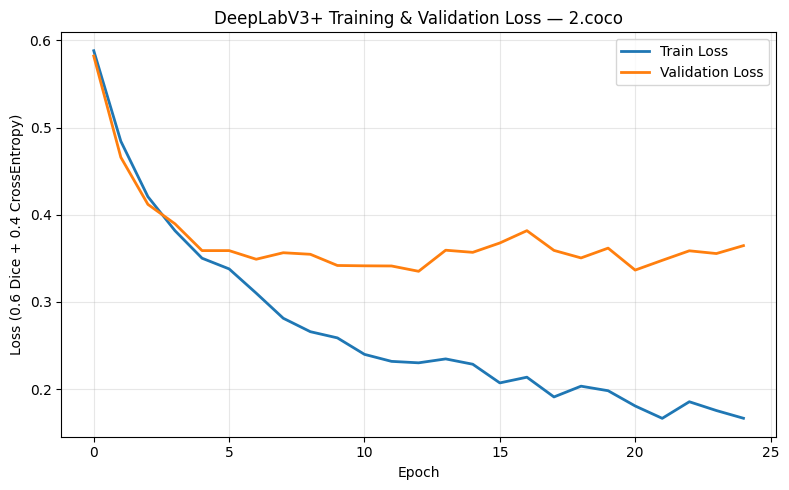

In [16]:
plt.figure(figsize=(8, 5))
plt.plot(history["train_loss"], label="Train Loss", linewidth=2)
plt.plot(history["val_loss"], label="Validation Loss", linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Loss (0.6 Dice + 0.4 CrossEntropy)")
plt.title("DeepLabV3+ Training & Validation Loss — 2.coco")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("loss_curve.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 13 — Load best checkpoint & run inference on Train, Validation, and Test

We evaluate all three splits — not just test — because comparing them is the fastest way to see *why* test performance falls short: a big gap between train and test metrics means the model memorized the training images rather than learning generalizable defect features (overfitting), which is the dominant risk with a dataset this size.

For a fair "training performance" number, we build a second, deterministic view of the training images (`train_eval_ds`) using the same no-augmentation transform as validation/test — evaluating on randomly-augmented training data would give a distorted (usually pessimistic) picture of what the model actually learned.

Two boosts applied at inference time only (they don't change what was trained, just how predictions are produced), used consistently across all three splits for a fair comparison:

- **Test-time augmentation (TTA)** — each image is also run horizontally- and vertically-flipped, and the three prediction probabilities are averaged.
- **Small-blob cleanup** — predicted defect regions smaller than `CFG.MIN_BLOB_AREA` pixels are treated as noise and reverted to background.

In [17]:
def remove_small_blobs(pred_mask, num_classes, min_area):
    """Revert tiny predicted foreground blobs (likely noise) back to background."""
    cleaned = pred_mask.copy()
    for cls in range(1, num_classes):  # skip background (class 0)
        cls_mask = (pred_mask == cls).astype(np.uint8)
        if cls_mask.sum() == 0:
            continue
        n_labels, labels_cc, stats, _ = cv2.connectedComponentsWithStats(cls_mask, connectivity=8)
        for label_id in range(1, n_labels):
            if stats[label_id, cv2.CC_STAT_AREA] < min_area:
                cleaned[labels_cc == label_id] = 0
    return cleaned


@torch.no_grad()
def predict_with_tta(model, images):
    """Average softmax probabilities across original + h-flip + v-flip."""
    probs = torch.softmax(model(images), dim=1)

    probs_h = torch.flip(torch.softmax(model(torch.flip(images, dims=[3])), dim=1), dims=[3])
    probs_v = torch.flip(torch.softmax(model(torch.flip(images, dims=[2])), dim=1), dims=[2])

    return (probs + probs_h + probs_v) / 3.0


def run_inference(loader, desc):
    """Run TTA + blob-cleanup inference over an entire loader, returning flattened
    (targets, preds) pixel arrays. Works for any batch size."""
    preds_list, targets_list = [], []
    with torch.no_grad():
        for images, masks in tqdm(loader, desc=desc):
            images = images.to(CFG.DEVICE)
            avg_probs = predict_with_tta(model, images)
            preds = torch.argmax(avg_probs, dim=1).cpu().numpy()  # (B, H, W)
            targets = masks.numpy()  # (B, H, W)
            for b in range(preds.shape[0]):
                pred_mask = remove_small_blobs(preds[b], CFG.NUM_CLASSES, CFG.MIN_BLOB_AREA)
                preds_list.append(pred_mask.reshape(-1))
                targets_list.append(targets[b].reshape(-1))
    return np.concatenate(targets_list), np.concatenate(preds_list)


model.load_state_dict(torch.load(CKPT_PATH, map_location=CFG.DEVICE))
model.eval()

# Deterministic (no augmentation) view of the training images, for a fair train-set score
train_eval_ds = COCOSegmentationDataset(CFG.TRAIN_DIR, CFG.TRAIN_ANN, cat_id_to_class, val_transform, multiplier=1)
train_eval_loader = DataLoader(train_eval_ds, batch_size=CFG.BATCH_SIZE, shuffle=False,
                                num_workers=CFG.NUM_WORKERS, pin_memory=True)

train_targets, train_preds = run_inference(train_eval_loader, "Train (eval mode)")
valid_targets, valid_preds = run_inference(valid_loader, "Validation")
test_targets, test_preds   = run_inference(test_loader, "Test (TTA)")

print(f"Train pixels: {len(train_targets):,} | Valid pixels: {len(valid_targets):,} | Test pixels: {len(test_targets):,}")

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!


Test (TTA): 100%|██████████| 6/6 [00:00<00:00, 16.20it/s]


Train pixels: 12,058,624 | Valid pixels: 3,407,872 | Test pixels: 1,572,864


## Step 14 — Confusion matrix (pixel-level, test set)

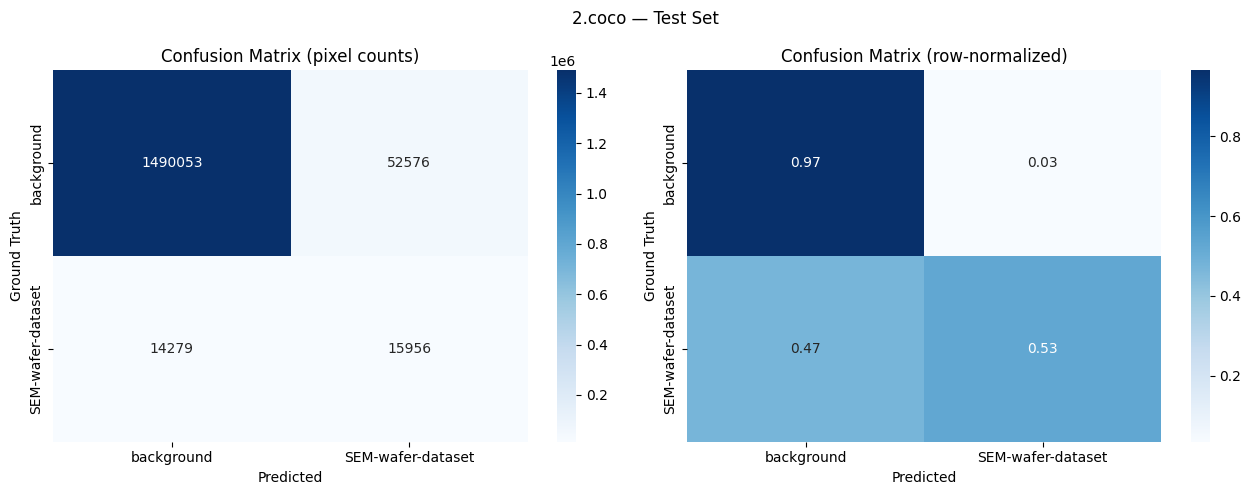

In [18]:
labels = list(range(CFG.NUM_CLASSES))
cm = confusion_matrix(test_targets, test_preds, labels=labels)
cm_norm = cm.astype(float) / (cm.sum(axis=1, keepdims=True) + 1e-9)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Ground Truth")
axes[0].set_title("Confusion Matrix (pixel counts)")

sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1])
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Ground Truth")
axes[1].set_title("Confusion Matrix (row-normalized)")

plt.suptitle("2.coco — Test Set")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 15 — Metrics table: Train / Validation / Test

The headline table: macro-averaged Precision, Recall, Accuracy, F1, and **F2** for each split side by side.

**Why F2 alongside F1:** F2 weights recall twice as heavily as precision (F1 weights them equally). Your model's error pattern so far has consistently been high recall / low precision (over-segmentation) — F1 penalizes that imbalance fairly harshly, while F2 reflects that catching real defects (recall) matters more here than avoiding every false positive, which is often the right trade-off for defect *detection* specifically. Watch the gap between rows too — Train much higher than Validation/Test is the signature of overfitting, and is the main thing worth reacting to on a dataset this size.

In [19]:
def compute_split_metrics(y_true, y_pred, label_list):
    precision = precision_score(y_true, y_pred, average="macro", labels=label_list, zero_division=0)
    recall = recall_score(y_true, y_pred, average="macro", labels=label_list, zero_division=0)
    f1 = f1_score(y_true, y_pred, average="macro", labels=label_list, zero_division=0)
    f2 = fbeta_score(y_true, y_pred, beta=2, average="macro", labels=label_list, zero_division=0)
    accuracy = accuracy_score(y_true, y_pred)
    return precision, recall, f1, f2, accuracy


rows = []
for split_name, y_true, y_pred in [
    ("Train", train_targets, train_preds),
    ("Validation", valid_targets, valid_preds),
    ("Test", test_targets, test_preds),
]:
    precision, recall, f1, f2, accuracy = compute_split_metrics(y_true, y_pred, labels)
    rows.append({
        "Dataset": split_name,
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "Accuracy": round(accuracy, 4),
        "F1 Score": round(f1, 4),
        "F2 Score": round(f2, 4),
    })

comparison_table = pd.DataFrame(rows)
comparison_table.to_csv("train_valid_test_metrics.csv", index=False)
comparison_table

,Dataset,Precision,Recall,Accuracy,F1 Score,F2 Score
0,Train,0.8717,0.9234,0.9857,0.8957,0.9118
1,Validation,0.8026,0.7677,0.9772,0.7840,0.7740
2,Test,0.6117,0.7468,0.9575,0.6506,0.6959


### Detailed per-class breakdown (Test set)

The summary table above macro-averages across classes; this expands the Test row into a per-class view, useful for diagnosing *which* class is dragging the score down.

In [20]:
precision_per_class = precision_score(test_targets, test_preds, average=None, labels=labels, zero_division=0)
recall_per_class = recall_score(test_targets, test_preds, average=None, labels=labels, zero_division=0)
f1_per_class = f1_score(test_targets, test_preds, average=None, labels=labels, zero_division=0)
f2_per_class = fbeta_score(test_targets, test_preds, beta=2, average=None, labels=labels, zero_division=0)

per_class_df = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Precision": np.round(precision_per_class, 4),
    "Recall": np.round(recall_per_class, 4),
    "F1-Score": np.round(f1_per_class, 4),
    "F2-Score": np.round(f2_per_class, 4),
})
per_class_df

,Class,Precision,Recall,F1-Score,F2-Score
0,background,0.9905,0.9659,0.9781,0.9707
1,SEM-wafer-dataset,0.2328,0.5277,0.3231,0.4211


## Step 16 — Visualize predictions vs ground truth

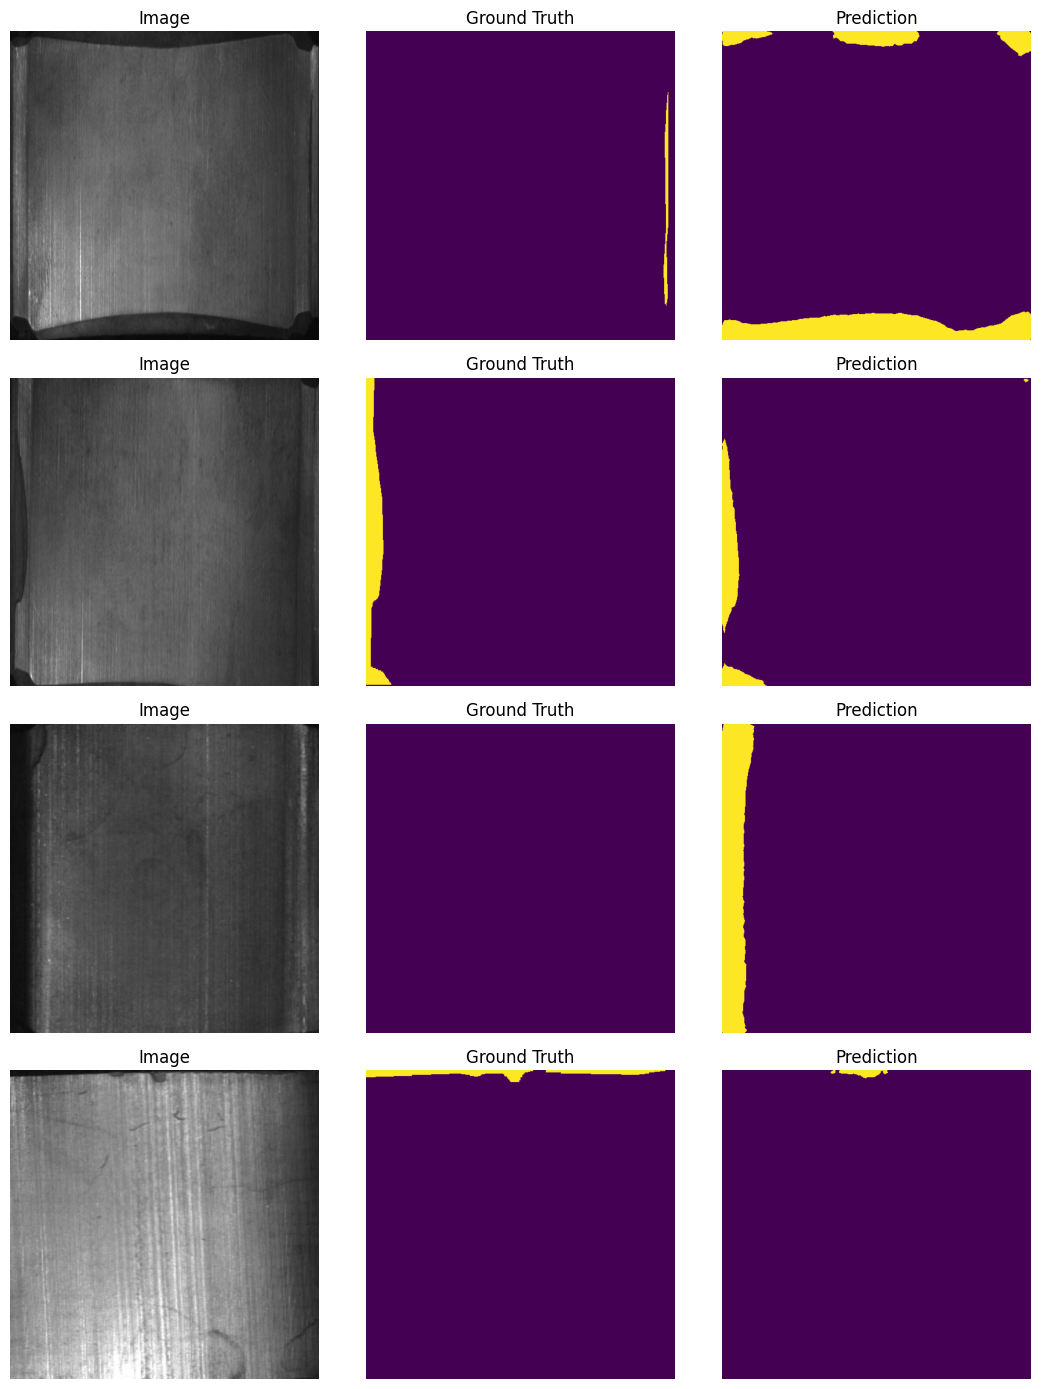

In [21]:
n_show = min(4, len(test_ds))
fig, axes = plt.subplots(n_show, 3, figsize=(11, 3.5 * n_show))
if n_show == 1:
    axes = axes.reshape(1, -1)

model.eval()
with torch.no_grad():
    for i in range(n_show):
        img, mask = test_ds[i]
        logits = model(img.unsqueeze(0).to(CFG.DEVICE))
        pred = torch.argmax(logits, dim=1).squeeze(0).cpu().numpy()

        axes[i, 0].imshow(denormalize(img))
        axes[i, 0].set_title("Image")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(mask.numpy(), cmap="viridis", vmin=0, vmax=CFG.NUM_CLASSES - 1)
        axes[i, 1].set_title("Ground Truth")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(pred, cmap="viridis", vmin=0, vmax=CFG.NUM_CLASSES - 1)
        axes[i, 2].set_title("Prediction")
        axes[i, 2].axis("off")

plt.tight_layout()
plt.savefig("predictions_sample.png", dpi=150, bbox_inches="tight")
plt.show()

## Output files

All saved to the Kaggle working directory (visible under *Output* once the notebook finishes running):

| File | Contents |
|---|---|
| `best_deeplabv3plus.pth` | Best model weights (lowest validation loss) |
| `loss_curve.png` | Train/validation loss curve |
| `confusion_matrix.png` | Pixel-wise confusion matrix (counts + normalized), test set |
| `train_valid_test_metrics.csv` | The Train / Validation / Test comparison table from Step 15 |
| `predictions_sample.png` | Qualitative predictions vs ground truth, test set |

## About the 85% accuracy / F1 target — and reading the Train/Validation/Test table

This notebook includes several things aimed specifically at pushing Test accuracy and F1 up, particularly by narrowing the **train/test gap** (the classic sign of overfitting on a small dataset):

- **Lighter encoder (`resnet18` instead of `resnet34`)** (Step 8) — fewer parameters means less capacity to memorize 46 training images instead of learning generalizable features.
- **Higher weight decay (`1e-3`)** (Step 10) — stronger L2 regularization.
- **`CoarseDropout` augmentation** (Step 5) — randomly occludes small patches during training, another standard overfitting countermeasure.
- **Placeholder-category filtering** (Step 3) — removes Roboflow's auto-generated empty category from the class list, so metrics only reflect real classes.
- **`CFG.TRAIN_MULTIPLIER = 2`** (Step 6) — each real training image is sampled 2x per epoch with independent random augmentation, tuned to this dataset's 46-image size.
- **Class-weighted, Dice-leaning loss** (Step 9) — up-weights the rare defect class and leans more on Dice (0.6) than CrossEntropy (0.4), which helps when recall is much higher than precision (over-segmentation).
- **Test-time augmentation + small-blob cleanup** (Step 13) — averages flipped predictions and discards tiny noisy blobs, applied consistently across Train/Validation/Test for a fair comparison.

**How to read the Step 15 table once you rerun this:** if Train is still much higher than Validation and Test, the gap (not the absolute Test number) is what to chase — it means the regularization above wasn't enough for this amount of data. If Train, Validation, and Test are now closer together but all landed below 0.85, that's a different problem: the model has genuinely learned what it can from 46 images, and more labeled data is the lever that matters, not more training tricks.

No code change can *guarantee* a specific number like 85% — that depends on your actual data. If you're still short after this run, in order of expected impact:

1. **More labeled images**, especially for `2.coco` if it's one of the smaller splits.
2. **Increase `CFG.MIN_BLOB_AREA`** if the confusion matrix shows scattered small false positives.
3. **Check annotation tightness** — loosely-drawn ground-truth polygons directly hurt precision.
4. If Train/Validation/Test are already close together, more capacity (`CFG.ENCODER = "resnet34"`) is worth trying — but only after confirming overfitting isn't still the dominant problem.
